# Autoregressive Model Training for target `delta_p`

This notebook trains direct multi-horizon models for:
- 1 hour ahead
- 24 hours ahead
- 48 hours ahead

Models trained:
- Decision Tree
- Random Forest
- SVR
- CatBoost
- XGBoost
- LightGBM
- MLP
- LSTM (TensorFlow/Keras)

In [85]:
import json
from utils.paths import DATASETS_PREPROCESSED_DIR
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, KFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
from matplotlib import pyplot as plt

Since RandomizedSearchCV handles internal cross-validation by automatically splitting 
the training data into train and validation folds, the train and validation sets 
can be merged into a single training set.

In [65]:
train_df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_train.csv")
val_df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_val.csv")
test_df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_test.csv")
df = pd.concat([train_df, val_df])
df

,time,temperature_2m,relative_humidity_2m,dew_point_2m,wind_speed_10m,wind_speed_100m,wind_gusts_10m,wind_sin_10m,wind_cos_10m,wind_sin_100m,wind_cos_100m,p_base,delta_p
0,2017-01-02 00:00:00,0.395392,0.817073,0.445396,0.0,0.000000,0.032143,0.559193,-0.829038,0.309017,-0.951057,0.005159,-0.005159
1,2017-01-02 01:00:00,0.394470,0.829268,0.447537,0.0,0.085413,0.139286,0.484810,-0.874620,0.374607,-0.927184,0.164120,-0.021720
2,2017-01-02 02:00:00,0.379724,0.890244,0.445396,0.0,0.000000,0.096429,0.529919,-0.848048,0.500000,-0.866025,0.005159,-0.005159
3,2017-01-02 03:00:00,0.385253,0.853659,0.443255,0.0,0.000000,0.039286,0.848048,0.529919,0.965926,-0.258819,0.005159,-0.005159
4,2017-01-02 04:00:00,0.384332,0.853659,0.441113,0.0,0.127639,0.125000,0.848048,0.529919,0.994522,0.104528,0.184905,-0.105605
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2020-12-31 19:00:00,0.348387,0.756098,0.377944,0.0,0.164107,0.121429,-0.996195,-0.087156,-0.997564,-0.069756,0.202639,0.002161
8756,2020-12-31 20:00:00,0.341014,0.768293,0.372591,0.0,0.135317,0.100000,-0.990268,-0.139173,-0.997564,-0.069756,0.209395,-0.012195
8757,2020-12-31 21:00:00,0.335484,0.792683,0.371520,0.0,0.043186,0.092857,-0.981627,0.190809,-0.984808,0.173648,0.146651,0.042949
8758,2020-12-31 22:00:00,0.329954,0.804878,0.370450,0.0,0.000000,0.057143,0.087156,0.996195,-0.731354,0.681998,0.005159,-0.005159


Adding some additional time series features might be beneficial for pattern identification.

In [66]:
def create_time_features(df):
    df = df.sort_values("time").reset_index(drop=True)
    df["time"] = pd.to_datetime(df["time"])
    df['hour'] = df['time'].dt.hour
    df['dayofweek'] = df['time'].dt.dayofweek
    df['month'] = df['time'].dt.month

    return df

df = create_time_features(df)
test_df = create_time_features(test_df)
test_df

,time,temperature_2m,relative_humidity_2m,dew_point_2m,wind_speed_10m,wind_speed_100m,wind_gusts_10m,wind_sin_10m,wind_cos_10m,wind_sin_100m,wind_cos_100m,p_base,delta_p,hour,dayofweek,month
0,2021-01-01 00:00:00,0.316129,0.878049,0.370450,0.0,0.000000,0.042857,-2.249511e-01,-0.974370,-0.809017,-0.587785,0.005159,-0.005159,0,4,1
1,2021-01-01 01:00:00,0.311521,0.890244,0.366167,0.0,0.000000,0.082143,-6.975647e-02,-0.997564,-0.309017,-0.951057,0.005159,-0.005159,1,4,1
2,2021-01-01 02:00:00,0.315207,0.865854,0.366167,0.0,0.000000,0.082143,2.923717e-01,-0.956305,0.207912,-0.978148,0.005159,-0.005159,2,4,1
3,2021-01-01 03:00:00,0.322581,0.829268,0.365096,0.0,0.084453,0.089286,2.249511e-01,-0.974370,0.309017,-0.951057,0.170930,-0.026730,3,4,1
4,2021-01-01 04:00:00,0.329032,0.792683,0.365096,0.0,0.090211,0.096429,-5.233596e-02,-0.998630,0.156434,-0.987688,0.164120,-0.027520,4,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2021-12-31 19:00:00,0.447005,0.926829,0.531049,0.0,0.000000,0.071429,7.986355e-01,0.601815,0.681998,-0.731354,0.005159,-0.005159,19,4,12
8756,2021-12-31 20:00:00,0.453456,0.926829,0.540685,0.0,0.115163,0.153571,8.290376e-01,0.559193,0.951057,0.309017,0.183725,0.022875,20,4,12
8757,2021-12-31 21:00:00,0.447005,0.939024,0.536403,0.0,0.000000,0.135714,-2.449294e-16,1.000000,0.707107,0.707107,0.005159,-0.005159,21,4,12
8758,2021-12-31 22:00:00,0.449770,0.951220,0.541756,0.0,0.145873,0.132143,7.071068e-01,0.707107,0.777146,0.629320,0.219564,0.041036,22,4,12


Next thing to do is vizualize how data will be split for model finetuning.

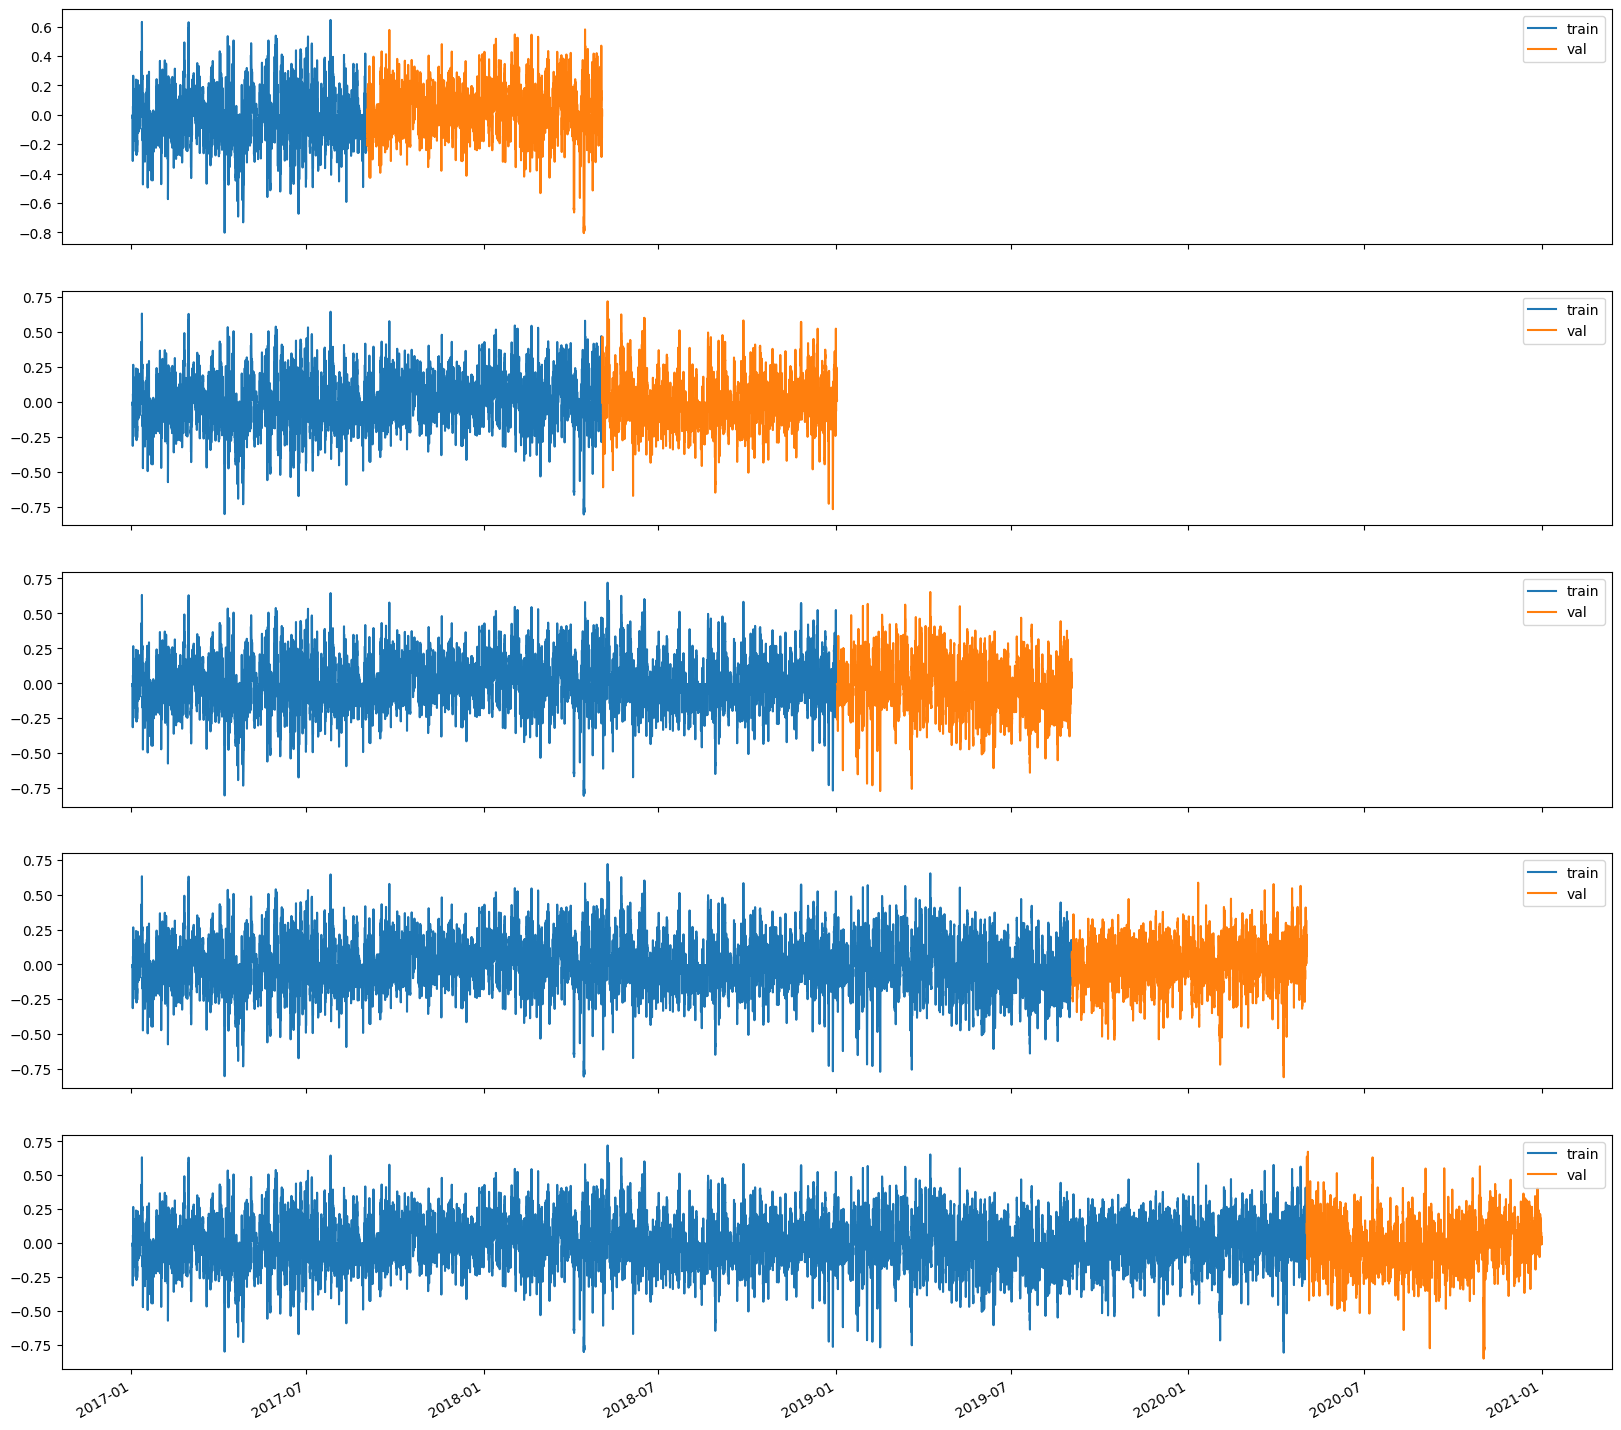

In [76]:
tss = TimeSeriesSplit(n_splits=5)

fig, axs = plt.subplots(5, 1, figsize=(20, 20), sharex=True)
fold = 0
for train_index, val_index in tss.split(df):
    train = df.iloc[train_index]
    val = df.iloc[val_index]
    axs[fold].plot(train["time"], train["delta_p"], label="train")
    axs[fold].plot(val["time"], val["delta_p"], label="val")
    axs[fold].legend()
    fold += 1
fig.autofmt_xdate()

A dedicated function handles lag feature engineering. Target lags (delta_p at t-1 through t-6, t-24, t-48) 
are selected based on ACF and PACF analysis of the target series. Feature lags are selected based 
on CCF analysis between each feature and the target. The prediction target is defined as delta_p 
shifted by -horizon, representing the value horizon steps ahead.

In [ ]:
TARGET_LAGS = [1, 2, 3, 4, 5, 6, 24, 48]

FEATURE_LAGS = {
    "temperature_2m": [1, 17],
    "relative_humidity_2m": [6, 30],
    "wind_speed_10m": [6, 30],
    "wind_gusts_10m": [6, 30],
}


def add_lags(df, target_lags, feature_lags, horizon):
    lagged = df.copy()

    for lag in target_lags:
        lagged[f"delta_p_lag_{lag}"] = lagged["delta_p"].shift(lag)

    for feature, lags in feature_lags.items():
        for lag in lags:
            lagged[f"{feature}_lag_{lag}"] = lagged[feature].shift(lag)

    lagged["target"] = lagged["delta_p"].shift(-horizon)
    
    lagged = lagged.dropna().reset_index(drop=True)

    return lagged

Fine tuning is done using RandomizedSearchCV

In [72]:
import pickle
from pathlib import Path

MODELS_DIR = Path("autoregression-models/models")
MODELS_DIR.mkdir(exist_ok=True)

all_best_params = {}

dt_params = {
    "max_depth": [None, 3, 5, 10, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": [None, "sqrt", "log2", 0.5],
    "criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "splitter": ["best", "random"],
}

rf_params = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [2, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [None, "sqrt", "log2", 0.5],
    "max_samples": [None, 0.7, 0.8, 0.9],
}

svr_params = {
    "C": [0.01, 0.1, 0.5, 1, 2],
    "epsilon": [0.01, 0.1, 0.5],
    "kernel": ["linear", "rbf", "poly", "sigmoid"],
    "gamma": ["scale", "auto"],
    "degree": [2, 3, 4],
    "coef0": [0.0, 0.1, 0.5, 1.0],
}

catboost_params = {
    "iterations": [100, 300, 500, 1000],
    "learning_rate": [0.01, 0.05, 0.1],
    "depth": [4, 6, 8, 10],
    "l2_leaf_reg": [1, 3, 5, 10],
    "verbose": [0],
}

xgboost_params = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 7, 10],
    "subsample": [0.5, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5, 1.0],
    "reg_lambda": [0, 0.1, 0.5, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3],
}

lgbm_params = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "num_leaves": [20, 31, 40, 50],
    "max_depth": [3, 5, 10, 15],
    "min_child_samples": [10, 20, 50],
    "subsample": [0.5, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5, 1.0],
    "reg_lambda": [0, 0.1, 0.5, 1.0],
    "verbose": [-1],
}

mlp_params = {
    "hidden_layer_sizes": [
        (32,),
        (64,),
        (32, 16),
        (64, 32),
        (32, 16, 8),
        (64, 32, 16),
    ],
    "activation": ["relu", "tanh"],
    "solver": ["adam", "sgd"],
    "alpha": [0.001, 0.01, 0.1],
    "learning_rate": ["constant", "adaptive"],
    "learning_rate_init": [0.001, 0.01, 0.05],
    "max_iter": [1000, 1500, 2000],
    "early_stopping": [True],
}

models = {
    "decision_tree": (DecisionTreeRegressor(random_state=42), dt_params),
    "random_forest": (RandomForestRegressor(random_state=42), rf_params),
    "svr": (SVR(max_iter=1000), svr_params),
    "catboost": (CatBoostRegressor(random_state=42), catboost_params),
    "xgboost": (XGBRegressor(random_state=42, objective="reg:squarederror"), xgboost_params),
    "lgbm": (LGBMRegressor(random_state=42), lgbm_params),
    "mlp": (MLPRegressor(random_state=42), mlp_params),
}

HORIZONS = [1, 24, 48]

metrics_rows = []
feature_drop_cols = ["time", "p_base", "delta_p", "target"]

for horizon in HORIZONS:
    print(f"=== Horizon {horizon}h ===")

    train_lagged = add_lags(df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)
    test_lagged = add_lags(test_df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)

    X_train = train_lagged.drop(columns=feature_drop_cols).copy()
    y_train = train_lagged["target"].copy()
    X_test = test_lagged.drop(columns=feature_drop_cols).copy()
    y_test = test_lagged["target"].copy()

    for model_name, (model, param_grid) in models.items():
        print(f"[{horizon}h] tuning model: {model_name}")

        grid_search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_grid,
            n_iter=50,
            cv=tss,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )

        grid_search.fit(X_train, y_train)
        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test)

        all_best_params[f"{model_name}_h{horizon}"] = grid_search.best_params_
        
        model_path = MODELS_DIR / f"{model_name}_h{horizon}.pkl"
        with open(model_path, "wb") as f:
            pickle.dump(best_model, f)

        metrics_rows.append(
            {
                "horizon": horizon,
                "model": model_name,
                "MAE": mean_absolute_error(y_test, y_pred),
                "RMSE": root_mean_squared_error(y_test, y_pred),
                "R2": r2_score(y_test, y_pred),
                "MAPE": mean_absolute_percentage_error(y_test, y_pred),
            }
        )

        print(f"[{horizon}h] done: {model_name} with {metrics_rows[-1]['RMSE']:.4f} RMSE")

classical_metrics_df = pd.DataFrame(metrics_rows).sort_index()
classical_metrics_df

=== Horizon 1h ===
[1h] tuning model: decision_tree
[1h] done: decision_tree with 0.1074 RMSE
[1h] tuning model: random_forest
[1h] done: random_forest with 0.1017 RMSE
[1h] tuning model: svr


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/l

[1h] done: svr with 0.1393 RMSE
[1h] tuning model: catboost
[1h] done: catboost with 0.0982 RMSE
[1h] tuning model: xgboost
[1h] done: xgboost with 0.1005 RMSE
[1h] tuning model: lgbm
[1h] done: lgbm with 0.0986 RMSE
[1h] tuning model: mlp


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_base.py:188: RuntimeWarning: overflow encountered in square
  0.5 * np.average((y_true - y_pred) ** 2, weights=sample_weight, axis=0).mean()
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_base.py:188: RuntimeWarning: overflow encountered in square
  0.5 * np.average((y_true - y_pred) ** 2, weights=sample_weight, axis=0).mean()
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/pytho

[1h] done: mlp with 0.1043 RMSE
=== Horizon 24h ===
[24h] tuning model: decision_tree
[24h] done: decision_tree with 0.1651 RMSE
[24h] tuning model: random_forest
[24h] done: random_forest with 0.1615 RMSE
[24h] tuning model: svr


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/l

... (2 outputs left out)

[24h] done: mlp with 0.1616 RMSE
=== Horizon 48h ===
[48h] tuning model: decision_tree
[48h] done: decision_tree with 0.1657 RMSE
[48h] tuning model: random_forest
[48h] done: random_forest with 0.1622 RMSE
[48h] tuning model: svr


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/l

[48h] done: svr with 0.1774 RMSE
[48h] tuning model: catboost
[48h] done: catboost with 0.1619 RMSE
[48h] tuning model: xgboost
[48h] done: xgboost with 0.1618 RMSE
[48h] tuning model: lgbm
[48h] done: lgbm with 0.1625 RMSE
[48h] tuning model: mlp
[48h] done: mlp with 0.1624 RMSE


,horizon,model,MAE,RMSE,R2,MAPE
0,1,decision_tree,0.076743,0.107450,0.567631,3.751129
1,1,random_forest,0.072191,0.101721,0.612505,3.533931
2,1,svr,0.107052,0.139326,0.273044,5.540852
3,1,catboost,0.069772,0.098179,0.639021,3.380595
4,1,xgboost,0.071649,0.100493,0.621805,3.415914
5,1,lgbm,0.070036,0.098564,0.636189,3.261234
6,1,mlp,0.075118,0.104342,0.592283,3.810314
7,24,decision_tree,0.122924,0.165082,-0.018126,1.111337
8,24,random_forest,0.121423,0.161518,0.025360,2.255603
9,24,svr,0.137642,0.179528,-0.204117,4.047635


In [74]:
from pathlib import Path

results_dir = Path("autoregression-models/results")

best_params_path = results_dir / "best_params_all.json"
metrics_path = results_dir / "classical_metrics_df.csv"

with open(best_params_path, "w", encoding="utf-8") as f:
    json.dump(all_best_params, f, indent=2)

classical_metrics_df.to_csv(metrics_path, index=False)

print(f"Saved best params to: {best_params_path}")
print(f"Saved classical metrics to: {metrics_path}")

Saved best params to: autoregression-models/results/best_params_all.json
Saved classical metrics to: autoregression-models/results/classical_metrics_df.csv


### Hybrid model

Now that standalone models for each time horizon was trained on best parameters, hybrid model migh be created. StackingRegressor from sklearn library will be used for that. Is stacking the output of individual esmiators and then it is used as input for final estimator. In each horizon, CatBoost was conducted as the best model, based on all MAE, RMSE, R2 and MAPE, so now it will be used as a final estimator. Other models will be used as base estimators.

In [83]:
HYBRID_MODELS_DIR = Path("autoregression-models/hybrid_models")
HYBRID_MODELS_DIR.mkdir(exist_ok=True)

hybrid_metrics_rows = []

for horizon in HORIZONS:
    print(f"=== Horizon {horizon}h ===")
    
    base_estimators = [
        ("decision_tree", DecisionTreeRegressor(**all_best_params[f"decision_tree_h{horizon}"])),
        ("random_forest", RandomForestRegressor(**all_best_params[f"random_forest_h{horizon}"])),
        ("svr",           SVR(**all_best_params[f"svr_h{horizon}"])),
        ("mlp",           MLPRegressor(**all_best_params[f"mlp_h{horizon}"])),
        ("lgbm",          LGBMRegressor(**all_best_params[f"lgbm_h{horizon}"])),
        ("xgboost",       XGBRegressor(**all_best_params[f"xgboost_h{horizon}"])),
    ]
    
    meta_model = CatBoostRegressor(**all_best_params[f"catboost_h{horizon}"])
     
    train_lagged = add_lags(df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)
    test_lagged = add_lags(test_df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)

    X_train = train_lagged.drop(columns=feature_drop_cols).copy()
    y_train = train_lagged["target"].copy()
    X_test = test_lagged.drop(columns=feature_drop_cols).copy()
    y_test = test_lagged["target"].copy()

    hybrid_model = StackingRegressor(
        estimators=base_estimators,
        final_estimator=meta_model,
        cv=KFold(n_splits=5, shuffle=False),
        n_jobs=-1,
    )
    
    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)
    
    hybrid_model_path = HYBRID_MODELS_DIR / f"stacking_regressor_h{horizon}.pkl"
    with open(hybrid_model_path, "wb") as f:
        pickle.dump(hybrid_model, f)

    hybrid_metrics_rows.append(
            {
                "horizon": horizon,
                "model": "hybrid_model",
                "MAE": mean_absolute_error(y_test, y_pred),
                "RMSE": root_mean_squared_error(y_test, y_pred),
                "R2": r2_score(y_test, y_pred),
                "MAPE": mean_absolute_percentage_error(y_test, y_pred),
            }
        )
    
    print(f"[{horizon}h] done with {hybrid_metrics_rows[-1]['RMSE']:.4f} RMSE")
    
hybrid_metrics_df = pd.DataFrame(hybrid_metrics_rows).sort_index()
hybrid_metrics_df

=== Horizon 1h ===
[1h] done with 0.0982 RMSE
=== Horizon 24h ===
[24h] done with 0.1610 RMSE
=== Horizon 48h ===
[48h] done with 0.1619 RMSE


,horizon,model,MAE,RMSE,R2,MAPE
0,1,hybrid_model,0.069717,0.098153,0.639216,3.277961
1,24,hybrid_model,0.121600,0.161022,0.031336,2.613770
2,48,hybrid_model,0.122510,0.161856,0.023730,2.415122


In [86]:
hybrid_metrics_path = results_dir / "hybrid_metrics_df.csv"
hybrid_metrics_df.to_csv(hybrid_metrics_path, index=False)
print(f"Saved classical metrics to: {hybrid_metrics_path}")

Saved classical metrics to: autoregression-models/results/hybrid_metrics_df.csv


The results show that the hybrid model achieves moderate predictive accuracy for the 1-hour horizon (R²=0.64, MAPE≈3.3%), but fails to capture meaningful variance at 24h and 48h horizons (R²≈0.03), where predictions are barely better than a naive baseline. This suggests the model is only capable of capturing short-term fluctuations in delta_p, while medium-term dynamics remain largely unexplained. A recursive forecasting approach using 1h model to iteratively reach 24h or 48h was considered, but rejected. Given the 1h model residual error, each iteration would introduce a new error contribution that propagates through model causing error accumulation.